
# 06 — Modelos de Machine Learning

## Taller de Análisis de Datos I — TP3

### Objetivo

Comparar dos modelos de corrección de pronósticos de temperatura:

- Ridge: modelo lineal orientado a la interpretabilidad.
- HistGradientBoosting: modelo no lineal orientado a reducir el error.

### Metodología

Se utiliza validación cruzada temporal expansiva con cuatro
particiones cronológicas.

En cada partición:

1. Los datos de entrenamiento preceden a los de validación.
2. Se eliminan etiquetas no disponibles al inicio de la validación.
3. El preprocesamiento se ajusta exclusivamente con entrenamiento.
4. Se calculan MAE, RMSE y sesgo para 12 y 24 horas.

Se mantienen congelados los hiperparámetros seleccionados
anteriormente.

Los resultados no modifican el modelo final ni la evaluación
independiente realizada en noviembre.


In [1]:

# ==========================================
# 06 - CELDA 1
# DATOS Y VALIDACIÓN CRUZADA TEMPORAL
# ==========================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

# ------------------------------------------
# 1. LOCALIZAR ARCHIVOS
# ------------------------------------------

raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

carpeta_datos = raiz / "datos_modelado"

ruta_datos = (
    carpeta_datos / "features_historicas_tp3.pkl.gz"
)

ruta_variables = (
    carpeta_datos / "variables_modelo_lags.json"
)

assert ruta_datos.is_file()
assert ruta_variables.is_file()

# ------------------------------------------
# 2. CARGAR DATOS HISTÓRICOS
# ------------------------------------------

df_ml = pd.read_pickle(
    ruta_datos,
    compression="gzip"
).reset_index(drop=True)

variables_ml = json.loads(
    ruta_variables.read_text(encoding="utf-8")
)

assert len(df_ml) == 854009
assert len(variables_ml) == 23
assert len(set(variables_ml)) == 23

faltantes = set(variables_ml) - set(df_ml.columns)
assert not faltantes, f"Faltan predictores: {faltantes}"

# ------------------------------------------
# 3. CONVERTIR FECHAS
# ------------------------------------------

columnas_fecha = [
    "target_time_utc",
    "collection_time_utc",
    "forecast_generated_at_utc",
    "observation_collection_hour_utc"
]

for columna in columnas_fecha:
    df_ml[columna] = pd.to_datetime(
        df_ml[columna],
        utc=True,
        errors="coerce"
    )

assert df_ml[columnas_fecha].notna().all().all()
assert np.isfinite(df_ml["error_c"]).all()

# ------------------------------------------
# 4. CONTROL DE DATOS RESERVADOS
# ------------------------------------------

assert (
    df_ml["target_time_utc"]
    < pd.Timestamp("2026-11-02", tz="UTC")
).all()

# La validación cruzada utiliza solo
# el período anterior al 18 de octubre.

corte_validacion_externa = pd.Timestamp(
    "2026-10-18",
    tz="UTC"
)

df_cv = df_ml.loc[
    df_ml["target_time_utc"]
    < corte_validacion_externa
].copy()

assert len(df_cv) == 680426

# ------------------------------------------
# 5. DISPONIBILIDAD DE CADA ETIQUETA
# ------------------------------------------

# Momento efectivo de emisión del pronóstico
emision_efectiva = df_cv[
    [
        "collection_time_utc",
        "forecast_generated_at_utc"
    ]
].max(axis=1)

# Momento estimado de disponibilidad
# de la observación
observacion_disponible = (
    df_cv["observation_collection_hour_utc"]
    + pd.Timedelta(hours=2)
)

# La etiqueta solo está disponible
# cuando se cumplen ambas condiciones.
disponibilidad_etiqueta = pd.concat(
    [
        emision_efectiva.rename("emision"),
        observacion_disponible.rename("observacion")
    ],
    axis=1
).max(axis=1)

assert disponibilidad_etiqueta.notna().all()

# ------------------------------------------
# 6. DEFINIR CUATRO FOLDS TEMPORALES
# ------------------------------------------

ventanas_cv = [
    ("2026-09-20", "2026-09-27"),
    ("2026-09-27", "2026-10-04"),
    ("2026-10-04", "2026-10-11"),
    ("2026-10-11", "2026-10-18")
]

folds_temporales = []
resumen_folds = []

for numero, (inicio_txt, fin_txt) in enumerate(
    ventanas_cv,
    start=1
):

    inicio = pd.Timestamp(inicio_txt, tz="UTC")
    fin = pd.Timestamp(fin_txt, tz="UTC")

    # Validación: rango semiabierto [inicio, fin)
    mascara_val = (
        (df_cv["target_time_utc"] >= inicio)
        & (df_cv["target_time_utc"] < fin)
    )

    indices_val = df_cv.index[mascara_val]

    assert len(indices_val) > 0

    # Primera emisión efectiva de validación
    primera_emision = (
        emision_efectiva.loc[indices_val].min()
    )

    # Entrenamiento cronológicamente anterior
    # y con etiqueta ya disponible.
    mascara_train = (
        (df_cv["target_time_utc"] < inicio)
        & (disponibilidad_etiqueta < primera_emision)
    )

    indices_train = df_cv.index[mascara_train]

    assert len(indices_train) > 0
    assert len(indices_train.intersection(indices_val)) == 0

    assert (
        disponibilidad_etiqueta.loc[indices_train]
        < primera_emision
    ).all()

    folds_temporales.append({
        "fold": numero,
        "train_idx": indices_train.to_numpy(),
        "val_idx": indices_val.to_numpy(),
        "primera_emision_val": primera_emision
    })

    resumen_folds.append({
        "fold": numero,
        "inicio_validacion": inicio.date(),
        "fin_exclusivo": fin.date(),
        "train_seguro": len(indices_train),
        "validacion": len(indices_val),
        "primera_emision_val": primera_emision
    })

# ------------------------------------------
# 7. MOSTRAR RESUMEN
# ------------------------------------------

df_resumen_cv = pd.DataFrame(resumen_folds)

print("DATOS HISTÓRICOS:")
print("Registros originales:", len(df_ml))
print("Registros disponibles para CV:", len(df_cv))
print("Características:", len(variables_ml))

print("\nPARTICIONES TEMPORALES:")
display(df_resumen_cv)

print("\nVARIABLES UTILIZADAS:")
print(variables_ml)

# ------------------------------------------
# 8. CONTROL FINAL
# ------------------------------------------

assert len(folds_temporales) == 4

assert all(
    len(f["train_idx"]) > 0
    and len(f["val_idx"]) > 0
    for f in folds_temporales
)

print("\nCONTROL FINAL:")
print("Cuatro particiones cronológicas construidas.")
print("Purga temporal aplicada por fold.")
print("Octubre 18 - noviembre 01 fuera de la CV.")
print("Noviembre 02-09 excluido.")
print("No se entrenaron modelos.")
print("Modelo final sin modificaciones.")


DATOS HISTÓRICOS:
Registros originales: 854009
Registros disponibles para CV: 680426
Características: 23

PARTICIONES TEMPORALES:


,fold,inicio_validacion,fin_exclusivo,train_seguro,validacion,primera_emision_val
0,1,2026-09-20,2026-09-27,149806,115125,2026-09-19 00:15:05.907413+00:00
1,2,2026-09-27,2026-10-04,265013,126746,2026-09-26 00:15:05.851838+00:00
2,3,2026-10-04,2026-10-11,388744,135282,2026-10-03 00:15:05.926487+00:00
3,4,2026-10-11,2026-10-18,523354,136353,2026-10-10 00:15:05.870864+00:00



VARIABLES UTILIZADAS:
['temperature_forecast_c', 'dewpoint_forecast_c', 'relative_humidity_forecast_pct', 'wind_speed_forecast_kmh', 'precip_probability_forecast_pct', 'latitude', 'longitude', 'horizon_target_hours', 'depresion_rocio_c', 'inversion_rocio_flag', 'humedad_cero_flag', 'viento_calma_flag', 'direccion_viento_sin', 'direccion_viento_cos', 'hora_utc_sin', 'hora_utc_cos', 'hora_solar_sin', 'hora_solar_cos', 'dia_anio_sin', 'dia_anio_cos', 'lag_error_disponible_c', 'lag_error_edad_h', 'lag_error_faltante_flag']

CONTROL FINAL:
Cuatro particiones cronológicas construidas.
Purga temporal aplicada por fold.
Octubre 18 - noviembre 01 fuera de la CV.
Noviembre 02-09 excluido.
No se entrenaron modelos.
Modelo final sin modificaciones.


In [2]:

# ==========================================
# 06 - CELDA 2
# VALIDACIÓN CRUZADA TEMPORAL - RIDGE
# ==========================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ------------------------------------------
# 1. IDENTIFICAR GRUPOS DE VARIABLES
# ------------------------------------------

variables_lag_numericas = [
    "lag_error_disponible_c",
    "lag_error_edad_h"
]

variable_lag_faltante = [
    "lag_error_faltante_flag"
]

variables_base_cv = [
    columna
    for columna in variables_ml
    if columna not in (
        variables_lag_numericas
        + variable_lag_faltante
    )
]

assert len(variables_base_cv) == 20
assert len(variables_lag_numericas) == 2
assert len(variable_lag_faltante) == 1

# ------------------------------------------
# 2. CONSTRUIR PREPROCESADOR INDEPENDIENTE
# ------------------------------------------

def crear_preprocesador_cv():

    transformacion_base = Pipeline([
        (
            "imputacion",
            SimpleImputer(strategy="median")
        ),
        (
            "escalado",
            StandardScaler()
        )
    ])

    transformacion_lags = Pipeline([
        (
            "imputacion",
            SimpleImputer(
                strategy="constant",
                fill_value=0
            )
        ),
        (
            "escalado",
            StandardScaler()
        )
    ])

    return ColumnTransformer(
        transformers=[
            (
                "variables_base",
                transformacion_base,
                variables_base_cv
            ),
            (
                "lags_numericos",
                transformacion_lags,
                variables_lag_numericas
            ),
            (
                "lag_faltante",
                "passthrough",
                variable_lag_faltante
            )
        ],
        remainder="drop"
    )

# ------------------------------------------
# 3. FUNCIÓN PARA CALCULAR MÉTRICAS
# ------------------------------------------

def metricas_cv(
    fold,
    horizonte,
    error_real,
    correccion
):

    residual_original = error_real
    residual_corregido = error_real - correccion

    mae_original = np.mean(
        np.abs(residual_original)
    )

    mae_corregido = np.mean(
        np.abs(residual_corregido)
    )

    return {
        "fold": fold,
        "horizonte_h": horizonte,
        "registros": len(error_real),
        "MAE_original_c": mae_original,
        "MAE_ridge_c": mae_corregido,
        "RMSE_original_c": np.sqrt(
            np.mean(residual_original ** 2)
        ),
        "RMSE_ridge_c": np.sqrt(
            np.mean(residual_corregido ** 2)
        ),
        "sesgo_original_c": np.mean(
            residual_original
        ),
        "sesgo_ridge_c": np.mean(
            residual_corregido
        ),
        "mejora_MAE_pct": (
            100 * (1 - mae_corregido / mae_original)
        )
    }

# ------------------------------------------
# 4. EJECUTAR LOS CUATRO FOLDS
# ------------------------------------------

resultados_ridge_cv = []
predicciones_ridge_cv = []

for fold_info in folds_temporales:

    numero = fold_info["fold"]

    indices_train = fold_info["train_idx"]
    indices_val = fold_info["val_idx"]

    # Conjuntos de entrenamiento y validación
    X_train = df_cv.loc[
        indices_train, variables_ml
    ].copy()

    X_val = df_cv.loc[
        indices_val, variables_ml
    ].copy()

    y_train = df_cv.loc[
        indices_train, "error_c"
    ].to_numpy(dtype=float)

    y_val = df_cv.loc[
        indices_val, "error_c"
    ].to_numpy(dtype=float)

    h_val = df_cv.loc[
        indices_val, "horizon_target_hours"
    ].to_numpy()

    # El preprocesador se crea y se ajusta
    # desde cero en cada fold.
    preprocesador = crear_preprocesador_cv()

    X_train_pre = (
        preprocesador
        .fit_transform(X_train)
        .astype("float32")
    )

    X_val_pre = (
        preprocesador
        .transform(X_val)
        .astype("float32")
    )

    assert X_train_pre.shape[1] == 23
    assert X_val_pre.shape[1] == 23

    assert np.isfinite(X_train_pre).all()
    assert np.isfinite(X_val_pre).all()

    # Modelo Ridge con parámetros congelados
    modelo_ridge = Ridge(
        alpha=10.0,
        solver="lsqr",
        max_iter=2000,
        tol=1e-5
    )

    modelo_ridge.fit(
        X_train_pre,
        y_train
    )

    pred_error = modelo_ridge.predict(
        X_val_pre
    )

    assert len(pred_error) == len(y_val)
    assert np.isfinite(pred_error).all()

    # Conservar predicciones fuera de entrenamiento
    predicciones_ridge_cv.append(
        pd.DataFrame({
            "indice_original": indices_val,
            "fold": numero,
            "horizonte_h": h_val,
            "error_real_c": y_val,
            "correccion_ridge_c": pred_error
        })
    )

    # Evaluación por horizonte
    for horizonte in [12, 24]:

        mascara = h_val == horizonte

        resultados_ridge_cv.append(
            metricas_cv(
                fold=numero,
                horizonte=horizonte,
                error_real=y_val[mascara],
                correccion=pred_error[mascara]
            )
        )

    # Evaluación global de cada fold
    resultados_ridge_cv.append(
        metricas_cv(
            fold=numero,
            horizonte="Global",
            error_real=y_val,
            correccion=pred_error
        )
    )

    print(
        f"Fold {numero} completado | "
        f"Train: {len(X_train):,} | "
        f"Validación: {len(X_val):,}"
    )

# ------------------------------------------
# 5. CONSOLIDAR RESULTADOS
# ------------------------------------------

df_cv_ridge = pd.DataFrame(
    resultados_ridge_cv
)

df_predicciones_ridge_cv = pd.concat(
    predicciones_ridge_cv,
    ignore_index=True
)

print("\nRESULTADOS RIDGE POR FOLD Y HORIZONTE:")

display(
    df_cv_ridge.loc[
        df_cv_ridge["horizonte_h"] != "Global"
    ].round(4)
)

# ------------------------------------------
# 6. MÉTRICAS CONSOLIDADAS
# ------------------------------------------

resultados_consolidados = []

for horizonte in [12, 24, "Global"]:

    if horizonte == "Global":
        datos = df_predicciones_ridge_cv
    else:
        datos = df_predicciones_ridge_cv.loc[
            df_predicciones_ridge_cv["horizonte_h"]
            == horizonte
        ]

    resultados_consolidados.append(
        metricas_cv(
            fold="CV consolidada",
            horizonte=horizonte,
            error_real=datos[
                "error_real_c"
            ].to_numpy(),
            correccion=datos[
                "correccion_ridge_c"
            ].to_numpy()
        )
    )

df_cv_ridge_consolidado = pd.DataFrame(
    resultados_consolidados
)

print("\nRESULTADOS CONSOLIDADOS:")
display(
    df_cv_ridge_consolidado.round(4)
)

# ------------------------------------------
# 7. CONTROLES FINALES
# ------------------------------------------

assert len(df_cv_ridge) == 12

assert len(df_predicciones_ridge_cv) == 513506

assert (
    df_predicciones_ridge_cv[
        "indice_original"
    ].is_unique
)

assert np.isfinite(
    df_predicciones_ridge_cv[
        "correccion_ridge_c"
    ]
).all()

assert (
    df_predicciones_ridge_cv["horizonte_h"]
    .isin([12, 24])
).all()

print("\nCONTROL FINAL:")
print("Ridge evaluado en cuatro folds temporales.")
print("Preprocesamiento independiente por fold.")
print("Hiperparámetros originales conservados.")
print("513506 predicciones fuera de entrenamiento.")
print("Sin utilización de noviembre.")
print("Modelo final sin modificaciones.")


Fold 1 completado | Train: 149,806 | Validación: 115,125
Fold 2 completado | Train: 265,013 | Validación: 126,746
Fold 3 completado | Train: 388,744 | Validación: 135,282
Fold 4 completado | Train: 523,354 | Validación: 136,353

RESULTADOS RIDGE POR FOLD Y HORIZONTE:


,fold,horizonte_h,registros,MAE_original_c,MAE_ridge_c,RMSE_original_c,RMSE_ridge_c,sesgo_original_c,sesgo_ridge_c,mejora_MAE_pct
0,1,12,57562,1.3746,1.4381,1.7767,1.8647,0.0167,-0.6998,-4.6155
1,1,24,57563,1.4508,1.5157,1.8741,1.9751,-0.0229,-0.7937,-4.4707
3,2,12,63380,1.3402,1.4890,1.7144,1.8404,-0.0118,0.7835,-11.0980
4,2,24,63366,1.4134,1.5035,1.8036,1.8631,0.0044,0.7636,-6.3763
6,3,12,67640,1.4373,1.3815,1.8218,1.7387,-0.0421,0.1828,3.8792
7,3,24,67642,1.5092,1.4211,1.9069,1.7857,-0.0876,0.1427,5.8357
9,4,12,68175,1.3912,1.3505,1.7593,1.6911,0.0120,0.2073,2.9234
10,4,24,68178,1.4687,1.4132,1.8467,1.7683,0.0063,0.1784,3.7753



RESULTADOS CONSOLIDADOS:


,fold,horizonte_h,registros,MAE_original_c,MAE_ridge_c,RMSE_original_c,RMSE_ridge_c,sesgo_original_c,sesgo_ridge_c,mejora_MAE_pct
0,CV consolidada,12,256757,1.3870,1.4125,1.7690,1.7808,-0.0071,0.1397,-1.8351
1,CV consolidada,24,256749,1.4617,1.4606,1.8585,1.8444,-0.0254,0.0955,0.0782
2,CV consolidada,Global,513506,1.4244,1.4365,1.8143,1.8129,-0.0163,0.1176,-0.8534



CONTROL FINAL:
Ridge evaluado en cuatro folds temporales.
Preprocesamiento independiente por fold.
Hiperparámetros originales conservados.
513506 predicciones fuera de entrenamiento.
Sin utilización de noviembre.
Modelo final sin modificaciones.


#### Interpretación de Ridge
Resultado global de Ridge en validación cruzada
−0,85 %
Variación del MAE respecto del pronóstico original. El valor negativo indica un empeoramiento.
MAE original
1,4244 °C

MAE Ridge
1,4365 °C



Rendimiento según el período
Fold	Ridge 12 h	Ridge 24 h
1	−4,62 %	−4,47 %
2	−11,10 %	−6,38 %
3	+3,88 %	+5,84 %
4	+2,92 %	+3,78 %

El comportamiento cambia considerablemente:
- Folds 1 y 2: Ridge empeoró el MAE. También introdujo sesgos residuales elevados, de aproximadamente ±0,7–0,8 °C.
- Folds 3 y 4: Ridge sí consiguió mejorar el pronóstico original en ambos horizontes.
- Resultado consolidado: la mejora de los últimos folds no alcanzó para compensar el empeoramiento de los primeros.

#### Validación cruzada temporal de HistGradientBoosting
Vamos a ejecutar HGB con la misma configuración que utilizamos en el Notebook 04:
- learning_rate=0.07
- max_iter=120
- max_leaf_nodes=15
- max_depth=6
- min_samples_leaf=80
- l2_regularization=10

In [3]:

# ==========================================
# 06 - CELDA 3
# VALIDACIÓN CRUZADA TEMPORAL - HGB
# ==========================================

import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor

# ------------------------------------------
# 1. FUNCIÓN DE MÉTRICAS
# ------------------------------------------

def evaluar_hgb_cv(
    fold,
    horizonte,
    error_real,
    correccion
):

    residual = error_real - correccion

    mae_original = np.mean(
        np.abs(error_real)
    )

    mae_hgb = np.mean(
        np.abs(residual)
    )

    return {
        "fold": fold,
        "horizonte_h": horizonte,
        "registros": len(error_real),
        "MAE_original_c": mae_original,
        "MAE_hgb_c": mae_hgb,
        "RMSE_original_c": np.sqrt(
            np.mean(error_real ** 2)
        ),
        "RMSE_hgb_c": np.sqrt(
            np.mean(residual ** 2)
        ),
        "sesgo_original_c": np.mean(
            error_real
        ),
        "sesgo_hgb_c": np.mean(
            residual
        ),
        "mejora_MAE_pct": (
            100 * (1 - mae_hgb / mae_original)
        )
    }

# ------------------------------------------
# 2. EJECUTAR LOS CUATRO FOLDS
# ------------------------------------------

resultados_hgb_cv = []
predicciones_hgb_cv = []

for fold_info in folds_temporales:

    numero = fold_info["fold"]

    indices_train = fold_info["train_idx"]
    indices_val = fold_info["val_idx"]

    X_train = df_cv.loc[
        indices_train, variables_ml
    ].copy()

    X_val = df_cv.loc[
        indices_val, variables_ml
    ].copy()

    y_train = df_cv.loc[
        indices_train, "error_c"
    ].to_numpy(dtype=float)

    y_val = df_cv.loc[
        indices_val, "error_c"
    ].to_numpy(dtype=float)

    h_val = df_cv.loc[
        indices_val, "horizon_target_hours"
    ].to_numpy()

    # Nuevo preprocesador para cada fold
    preprocesador = crear_preprocesador_cv()

    X_train_pre = (
        preprocesador
        .fit_transform(X_train)
        .astype("float32")
    )

    X_val_pre = (
        preprocesador
        .transform(X_val)
        .astype("float32")
    )

    assert X_train_pre.shape[1] == 23
    assert X_val_pre.shape[1] == 23

    assert np.isfinite(X_train_pre).all()
    assert np.isfinite(X_val_pre).all()

    # Misma configuración del Notebook 04
    modelo_hgb = HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.07,
        max_iter=120,
        max_leaf_nodes=15,
        max_depth=6,
        min_samples_leaf=80,
        l2_regularization=10.0,
        early_stopping=False,
        random_state=42
    )

    modelo_hgb.fit(
        X_train_pre,
        y_train
    )

    pred_error = modelo_hgb.predict(
        X_val_pre
    )

    assert len(pred_error) == len(y_val)
    assert np.isfinite(pred_error).all()

    # Guardar predicciones fuera de entrenamiento
    predicciones_hgb_cv.append(
        pd.DataFrame({
            "indice_original": indices_val,
            "fold": numero,
            "horizonte_h": h_val,
            "error_real_c": y_val,
            "correccion_hgb_c": pred_error
        })
    )

    # Métricas por horizonte
    for horizonte in [12, 24]:

        mascara = h_val == horizonte

        resultados_hgb_cv.append(
            evaluar_hgb_cv(
                fold=numero,
                horizonte=horizonte,
                error_real=y_val[mascara],
                correccion=pred_error[mascara]
            )
        )

    # Métricas globales del fold
    resultados_hgb_cv.append(
        evaluar_hgb_cv(
            fold=numero,
            horizonte="Global",
            error_real=y_val,
            correccion=pred_error
        )
    )

    print(
        f"Fold {numero} completado | "
        f"Train: {len(X_train):,} | "
        f"Validación: {len(X_val):,}"
    )

# ------------------------------------------
# 3. CONSOLIDAR PREDICCIONES
# ------------------------------------------

df_cv_hgb = pd.DataFrame(
    resultados_hgb_cv
)

df_predicciones_hgb_cv = pd.concat(
    predicciones_hgb_cv,
    ignore_index=True
)

print("\nRESULTADOS HGB POR FOLD Y HORIZONTE:")

display(
    df_cv_hgb.loc[
        df_cv_hgb["horizonte_h"] != "Global"
    ].round(4)
)

# ------------------------------------------
# 4. RESULTADOS CONSOLIDADOS
# ------------------------------------------

resultados_consolidados_hgb = []

for horizonte in [12, 24, "Global"]:

    if horizonte == "Global":
        datos = df_predicciones_hgb_cv
    else:
        datos = df_predicciones_hgb_cv.loc[
            df_predicciones_hgb_cv["horizonte_h"]
            == horizonte
        ]

    resultados_consolidados_hgb.append(
        evaluar_hgb_cv(
            fold="CV consolidada",
            horizonte=horizonte,
            error_real=datos[
                "error_real_c"
            ].to_numpy(),
            correccion=datos[
                "correccion_hgb_c"
            ].to_numpy()
        )
    )

df_cv_hgb_consolidado = pd.DataFrame(
    resultados_consolidados_hgb
)

print("\nRESULTADOS HGB CONSOLIDADOS:")

display(
    df_cv_hgb_consolidado.round(4)
)

# ------------------------------------------
# 5. COMPARAR RIDGE Y HGB
# ------------------------------------------

comparacion_cv = (
    df_cv_ridge_consolidado[
        [
            "horizonte_h",
            "registros",
            "MAE_original_c",
            "MAE_ridge_c",
            "RMSE_ridge_c",
            "sesgo_ridge_c"
        ]
    ]
    .merge(
        df_cv_hgb_consolidado[
            [
                "horizonte_h",
                "registros",
                "MAE_original_c",
                "MAE_hgb_c",
                "RMSE_hgb_c",
                "sesgo_hgb_c"
            ]
        ],
        on=["horizonte_h", "registros"],
        suffixes=("_ridge", "_hgb"),
        validate="one_to_one"
    )
)

assert np.allclose(
    comparacion_cv["MAE_original_c_ridge"],
    comparacion_cv["MAE_original_c_hgb"]
)

comparacion_cv["MAE_original_c"] = (
    comparacion_cv["MAE_original_c_ridge"]
)

comparacion_cv["mejora_ridge_pct"] = (
    100 * (
        1
        - comparacion_cv["MAE_ridge_c"]
        / comparacion_cv["MAE_original_c"]
    )
)

comparacion_cv["mejora_hgb_pct"] = (
    100 * (
        1
        - comparacion_cv["MAE_hgb_c"]
        / comparacion_cv["MAE_original_c"]
    )
)

print("\nCOMPARACIÓN CONSOLIDADA:")

display(
    comparacion_cv[
        [
            "horizonte_h",
            "registros",
            "MAE_original_c",
            "MAE_ridge_c",
            "MAE_hgb_c",
            "mejora_ridge_pct",
            "mejora_hgb_pct"
        ]
    ].round(4)
)

# ------------------------------------------
# 6. CONTROLES FINALES
# ------------------------------------------

assert len(df_cv_hgb) == 12

assert len(df_predicciones_hgb_cv) == 513506

assert (
    df_predicciones_hgb_cv[
        "indice_original"
    ].is_unique
)

assert np.isfinite(
    df_predicciones_hgb_cv[
        "correccion_hgb_c"
    ]
).all()

assert len(comparacion_cv) == 3

print("\nCONTROL FINAL:")
print("HistGradientBoosting evaluado en 4 folds.")
print("Preprocesamiento ajustado por fold.")
print("Mismos folds utilizados para Ridge.")
print("513506 predicciones fuera de entrenamiento.")
print("Hiperparámetros HGB sin cambios.")
print("Octubre 18 - noviembre 01 excluido de la CV.")
print("Noviembre 02-09 no utilizado.")
print("Modelo final sin modificaciones.")


Fold 1 completado | Train: 149,806 | Validación: 115,125
Fold 2 completado | Train: 265,013 | Validación: 126,746
Fold 3 completado | Train: 388,744 | Validación: 135,282
Fold 4 completado | Train: 523,354 | Validación: 136,353

RESULTADOS HGB POR FOLD Y HORIZONTE:


,fold,horizonte_h,registros,MAE_original_c,MAE_hgb_c,RMSE_original_c,RMSE_hgb_c,sesgo_original_c,sesgo_hgb_c,mejora_MAE_pct
0,1,12,57562,1.3746,1.2932,1.7767,1.6772,0.0167,-0.3539,5.9257
1,1,24,57563,1.4508,1.3696,1.8741,1.7808,-0.0229,-0.4874,5.5975
3,2,12,63380,1.3402,1.2426,1.7144,1.5939,-0.0118,-0.0387,7.2874
4,2,24,63366,1.4134,1.2969,1.8036,1.6575,0.0044,-0.0407,8.2457
6,3,12,67640,1.4373,1.2275,1.8218,1.5892,-0.0421,-0.2183,14.5920
7,3,24,67642,1.5092,1.2881,1.9069,1.6613,-0.0876,-0.2325,14.6511
9,4,12,68175,1.3912,1.2764,1.7593,1.6223,0.0120,0.0516,8.2534
10,4,24,68178,1.4687,1.3448,1.8467,1.7033,0.0063,0.0584,8.4347



RESULTADOS HGB CONSOLIDADOS:


,fold,horizonte_h,registros,MAE_original_c,MAE_hgb_c,RMSE_original_c,RMSE_hgb_c,sesgo_original_c,sesgo_hgb_c,mejora_MAE_pct
0,CV consolidada,12,256757,1.3870,1.2589,1.7690,1.6192,-0.0071,-0.1327,9.2362
1,CV consolidada,24,256749,1.4617,1.3236,1.8585,1.6990,-0.0254,-0.1651,9.4492
2,CV consolidada,Global,513506,1.4244,1.2912,1.8143,1.6596,-0.0163,-0.1489,9.3455



COMPARACIÓN CONSOLIDADA:


,horizonte_h,registros,MAE_original_c,MAE_ridge_c,MAE_hgb_c,mejora_ridge_pct,mejora_hgb_pct
0,12,256757,1.3870,1.4125,1.2589,-1.8351,9.2362
1,24,256749,1.4617,1.4606,1.3236,0.0782,9.4492
2,Global,513506,1.4244,1.4365,1.2912,-0.8534,9.3455



CONTROL FINAL:
HistGradientBoosting evaluado en 4 folds.
Preprocesamiento ajustado por fold.
Mismos folds utilizados para Ridge.
513506 predicciones fuera de entrenamiento.
Hiperparámetros HGB sin cambios.
Octubre 18 - noviembre 01 excluido de la CV.
Noviembre 02-09 no utilizado.
Modelo final sin modificaciones.


#### Hallazgos importantes
- HGB mejoró en los ocho casos: cuatro folds por dos horizontes.
- Ridge tuvo resultados más variables: empeoró durante los primeros dos folds y mejoró durante los últimos dos.
- El mayor beneficio de HGB se produjo en el fold 3, con mejoras de aproximadamente 14,6 %.
- HGB no eliminó completamente el sesgo: el sesgo global pasó de −0,0163 °C en el pronóstico original a −0,1489 °C después de la corrección. Es decir, ganó precisión según MAE y RMSE, pero empeoró el sesgo firmado medio.
Este último resultado debe aparecer en las conclusiones para que el informe no confunda mejorar la precisión con corregir totalmente el sesgo.

COMPARACIÓN POR FOLD:


,fold,horizonte_h,registros,MAE_original_c,MAE_ridge_c,MAE_hgb_c,mejora_ridge_pct,mejora_hgb_pct,ventaja_hgb_c
0,1,12,57562,1.3746,1.4381,1.2932,-4.6155,5.9257,0.1449
1,1,24,57563,1.4508,1.5157,1.3696,-4.4707,5.5975,0.1461
2,1,Global,115125,1.4127,1.4769,1.3314,-4.5411,5.7572,0.1455
3,2,12,63380,1.3402,1.4890,1.2426,-11.0980,7.2874,0.2464
4,2,24,63366,1.4134,1.5035,1.2969,-6.3763,8.2457,0.2067
5,2,Global,126746,1.3768,1.4962,1.2697,-8.6746,7.7792,0.2265
6,3,12,67640,1.4373,1.3815,1.2275,3.8792,14.5920,0.1540
7,3,24,67642,1.5092,1.4211,1.2881,5.8357,14.6511,0.1330
8,3,Global,135282,1.4732,1.4013,1.2578,4.8813,14.6223,0.1435
9,4,12,68175,1.3912,1.3505,1.2764,2.9234,8.2534,0.0742



ESTABILIDAD TEMPORAL:


,horizonte_h,folds_evaluados,ridge_mejora_folds,hgb_mejora_folds,hgb_supera_ridge_folds
0,12,4,2,4,4
1,24,4,2,4,4


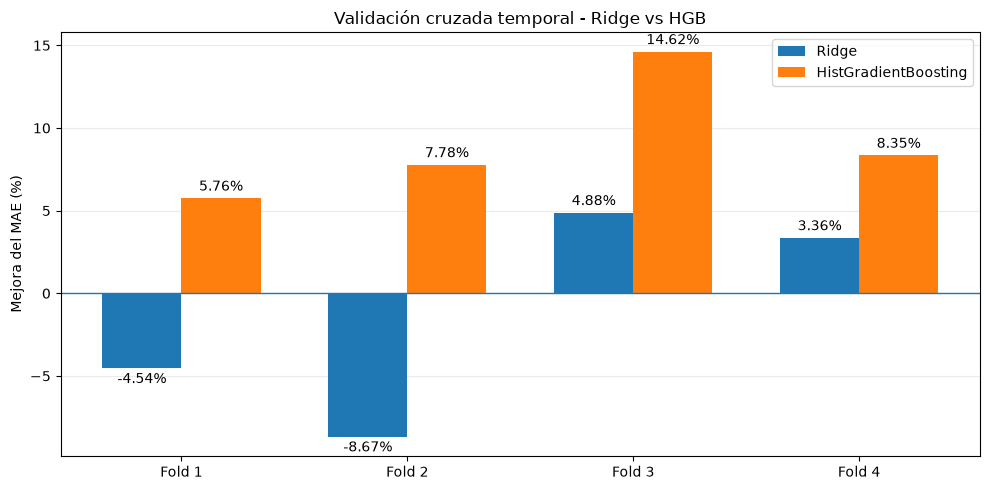


ARCHIVOS GENERADOS:
01_comparacion_por_fold.csv - 1639 bytes
02_comparacion_consolidada.csv - 851 bytes
03_estabilidad_temporal.csv - 115 bytes
04_ridge_vs_hgb_folds.png - 52676 bytes

CONTROL FINAL:
Ridge y HGB comparados en cuatro folds.
Resultados por horizonte y globales conservados.
Estabilidad temporal verificada.
No se entrenaron nuevos modelos.
Prueba final de noviembre sin modificaciones.
Notebook 06 listo para cierre.


In [4]:

# ==========================================
# 06 - CELDA 4
# COMPARACIÓN FINAL Y EXPORTACIÓN
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. COMPROBAR LOS RESULTADOS DISPONIBLES
# ------------------------------------------

assert len(df_cv_ridge) == 12
assert len(df_cv_hgb) == 12

assert len(df_cv_ridge_consolidado) == 3
assert len(df_cv_hgb_consolidado) == 3

assert len(df_predicciones_ridge_cv) == 513506
assert len(df_predicciones_hgb_cv) == 513506

# ------------------------------------------
# 2. COMPARAR AMBOS MODELOS POR FOLD
# ------------------------------------------

columnas_clave = [
    "fold",
    "horizonte_h",
    "registros"
]

ridge = df_cv_ridge[
    columnas_clave
    + ["MAE_original_c", "MAE_ridge_c",
       "mejora_MAE_pct"]
].rename(columns={
    "mejora_MAE_pct": "mejora_ridge_pct"
})

hgb = df_cv_hgb[
    columnas_clave
    + ["MAE_original_c", "MAE_hgb_c",
       "mejora_MAE_pct"]
].rename(columns={
    "mejora_MAE_pct": "mejora_hgb_pct"
})

df_comparacion_folds = ridge.merge(
    hgb,
    on=columnas_clave,
    suffixes=("_ridge", "_hgb"),
    validate="one_to_one"
)

assert len(df_comparacion_folds) == 12

assert np.allclose(
    df_comparacion_folds["MAE_original_c_ridge"],
    df_comparacion_folds["MAE_original_c_hgb"]
)

df_comparacion_folds["MAE_original_c"] = (
    df_comparacion_folds["MAE_original_c_ridge"]
)

df_comparacion_folds["ventaja_hgb_c"] = (
    df_comparacion_folds["MAE_ridge_c"]
    - df_comparacion_folds["MAE_hgb_c"]
)

columnas_presentacion = [
    "fold",
    "horizonte_h",
    "registros",
    "MAE_original_c",
    "MAE_ridge_c",
    "MAE_hgb_c",
    "mejora_ridge_pct",
    "mejora_hgb_pct",
    "ventaja_hgb_c"
]

print("COMPARACIÓN POR FOLD:")
display(
    df_comparacion_folds[
        columnas_presentacion
    ].round(4)
)

# ------------------------------------------
# 3. ESTABILIDAD TEMPORAL
# ------------------------------------------

df_folds_horizonte = df_comparacion_folds.loc[
    df_comparacion_folds["horizonte_h"]
    .isin([12, 24])
].copy()

resumen_estabilidad = []

for horizonte in [12, 24]:

    datos = df_folds_horizonte.loc[
        df_folds_horizonte["horizonte_h"]
        == horizonte
    ]

    resumen_estabilidad.append({
        "horizonte_h": horizonte,
        "folds_evaluados": len(datos),
        "ridge_mejora_folds": int(
            (datos["mejora_ridge_pct"] > 0).sum()
        ),
        "hgb_mejora_folds": int(
            (datos["mejora_hgb_pct"] > 0).sum()
        ),
        "hgb_supera_ridge_folds": int(
            (datos["MAE_hgb_c"]
             < datos["MAE_ridge_c"]).sum()
        )
    })

df_estabilidad_cv = pd.DataFrame(
    resumen_estabilidad
)

print("\nESTABILIDAD TEMPORAL:")
display(df_estabilidad_cv)

# ------------------------------------------
# 4. GRÁFICO DE MEJORA GLOBAL POR FOLD
# ------------------------------------------

global_folds = (
    df_comparacion_folds.loc[
        df_comparacion_folds["horizonte_h"]
        == "Global"
    ]
    .sort_values("fold")
)

x = np.arange(len(global_folds))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

barras_ridge = ax.bar(
    x - ancho / 2,
    global_folds["mejora_ridge_pct"],
    width=ancho,
    label="Ridge"
)

barras_hgb = ax.bar(
    x + ancho / 2,
    global_folds["mejora_hgb_pct"],
    width=ancho,
    label="HistGradientBoosting"
)

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"Fold {n}" for n in global_folds["fold"]]
)

ax.set_ylabel("Mejora del MAE (%)")
ax.set_title(
    "Validación cruzada temporal - Ridge vs HGB"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.bar_label(
    barras_ridge,
    fmt="%.2f%%",
    padding=3
)

ax.bar_label(
    barras_hgb,
    fmt="%.2f%%",
    padding=3
)

fig.tight_layout()

# ------------------------------------------
# 5. EXPORTAR RESULTADOS
# ------------------------------------------

carpeta_cv = (
    raiz / "resultados_ml" / "validacion_cruzada"
)

carpeta_cv.mkdir(
    parents=True,
    exist_ok=True
)

df_comparacion_folds[
    columnas_presentacion
].to_csv(
    carpeta_cv / "01_comparacion_por_fold.csv",
    index=False,
    encoding="utf-8-sig"
)

comparacion_cv.to_csv(
    carpeta_cv / "02_comparacion_consolidada.csv",
    index=False,
    encoding="utf-8-sig"
)

df_estabilidad_cv.to_csv(
    carpeta_cv / "03_estabilidad_temporal.csv",
    index=False,
    encoding="utf-8-sig"
)

fig.savefig(
    carpeta_cv / "04_ridge_vs_hgb_folds.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------
# 6. VERIFICACIONES FINALES
# ------------------------------------------

assert (
    df_estabilidad_cv["hgb_mejora_folds"] == 4
).all()

assert (
    df_estabilidad_cv["hgb_supera_ridge_folds"] == 4
).all()

assert len(list(carpeta_cv.glob("*.csv"))) == 3
assert len(list(carpeta_cv.glob("*.png"))) == 1

print("\nARCHIVOS GENERADOS:")

for archivo in sorted(carpeta_cv.iterdir()):
    if archivo.is_file():
        print(
            archivo.name,
            "-",
            archivo.stat().st_size,
            "bytes"
        )

print("\nCONTROL FINAL:")
print("Ridge y HGB comparados en cuatro folds.")
print("Resultados por horizonte y globales conservados.")
print("Estabilidad temporal verificada.")
print("No se entrenaron nuevos modelos.")
print("Prueba final de noviembre sin modificaciones.")
print("Notebook 06 listo para cierre.")
